In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
from scipy import stats

In [2]:
DATA_PATH = '../../data'
MERGEGEN_RESULTS = '../../mergeGen/RESULTS'
SBCR_RESULTS = '../../sbcr'

MERGEGEN_DATASET2 = f"{MERGEGEN_RESULTS}/mergeGen_dataset2_CSharp_model_dataset2_CSharp_similarities.csv"

SBCR_DATASET2 = f"{SBCR_RESULTS}/rq2_CSharp/RESULTS/results_evaluate_dataset2_CSharp_combination_rq2_CSharp_seed-3022024.xlsx"

DATASET2_COMPLETE = f"{DATA_PATH}/dataset2_CSharp_complete.json" 
DATASET2_TESTING = f"{DATA_PATH}/dataset2_CSharp_testing.json"
DATASET2_METADATA = f"{DATA_PATH}/dataset2_CSharp_metadata.json"

## Dataset2

In [3]:
df_complete = pd.read_json(DATASET2_COMPLETE)

In [4]:
df_test = pd.read_json(DATASET2_TESTING)
df_test

,all_raw_base,all_raw_a,all_raw_b,all_raw_res,merge_id,chunk_number
0,if( !lbItems.IsEnabled )\n,\n lbItems.ItemsSource = _sys.Items;\...,\n if( !lbItems.IsEnabled ) \n,\n lbItems.ItemsSource = _sys.Items;\...,42525,8
1,using (var httpClient = new Servic...,using (var httpClient = new Servic...,\n using (var httpClient = new Json...,using (var httpClient = new JsonHt...,3742,1
2,var metadata = new Metadata {\...,var metadata = new Metadata {\...,\n var metadata = new Metadata\...,var metadata = new Metadata\n ...,72657,2
3,foreach (var sho in items) {\n va...,foreach (var sho in items) {\n va...,\n\t\t\tforeach (var sho in items) {\n\t\t\t\t...,foreach (var sho in items) {\n va...,85061,2
4,"\t\t\t\t\tDebugLocation(484, 28);\n","\t\t\t\t\tDebugLocation(490, 28);\n","\n\t\t\t\t\tDebugLocation(488, 28);\n","\t\t\t\t\tDebugLocation(494, 28);\n",68052,278
...,...,...,...,...,...,...
2065,this.deleteAllUntrackedFilesToolSt...,this.deleteAllUntrackedFilesToolSt...,\n this.deleteAllUntrackedFilesTool...,this.deleteAllUntrackedFilesToolSt...,52592,10
2066,﻿using System;\nusing System.Collections.Gener...,﻿using System;\nusing System.Collections.Gener...,\n﻿using System;\nusing System.Collections.Gen...,﻿using System;\nusing System.Collections.Gener...,76818,1
2067,// parameter locations\n ...,// parameter locations\n ...,\n,,63854,1
2068,"#line 204 ""C:\Dev\Repos\AWSDotNetP...","#line 204 ""C:\Users\costleya\Work\...","\n #line 228 ""C:\Dev\Repos\AWSDotNe...","#line 230 ""C:\Users\costleya\Work\...",46667,61


In [5]:
df_mergegen = pd.read_csv(MERGEGEN_DATASET2)
data = []
for index, row in df_mergegen.iterrows():
    chunk = df_complete.iloc[row['chunk_index']]
    chunk_id = f"{chunk['merge_id']}-{chunk['chunk_number']}"
    data.append(chunk_id)
df_mergegen['chunk_id'] = data
df_mergegen = df_mergegen.rename(columns={"complete_similarity": "sim_mergegen", "time": "time_mergegen", "similarity":"sim_mergegen_trunc", "parents_similarity":"mergegen_parents_sim"})
df_mergegen.sort_values('chunk_id')
df_mergegen

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim,result,chunk_id
0,11446,0.890909,0.884615,0.278662,0.649351,1.000000,0.824675,FAIL,86686-1
1,18748,0.992537,0.992063,0.331669,1.000000,0.634921,0.817460,FAIL,78151-14
2,8935,0.853333,0.283531,1.341049,0.221239,0.290155,0.255697,FAIL,71211-1
3,2518,0.616162,0.622951,0.138654,0.615385,0.622951,0.619168,FAIL,29420-6
4,12021,0.581395,0.550000,0.099027,0.688525,0.644068,0.666296,FAIL,86841-1
...,...,...,...,...,...,...,...,...,...
2065,17894,1.000000,1.000000,0.092459,0.433213,0.956522,0.694867,SUCCEED,62386-1
2066,17318,1.000000,1.000000,0.385109,0.854237,1.000000,0.927119,SUCCEED,18039-20
2067,2351,0.641004,0.881188,1.341271,0.881188,0.881188,0.881188,SUCCEED,74349-2
2068,6790,1.000000,1.000000,0.073513,0.500000,1.000000,0.750000,SUCCEED,29925-32


In [6]:
df_mergegen.describe()

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim
count,2070.000000,2070.000000,2070.000000,2070.000000,2070.000000,2070.000000,2070.000000
mean,10368.984058,0.889966,0.878201,0.413602,0.703149,0.726593,0.714871
std,5880.124748,0.221988,0.250110,0.420956,0.298172,0.313186,0.204303
min,4.000000,0.000000,0.000000,0.026307,0.000000,0.000000,0.000000
25%,5228.250000,0.894737,0.911673,0.125672,0.500000,0.585774,0.597028
50%,10471.500000,1.000000,1.000000,0.238338,0.805970,0.857143,0.750000
75%,15429.250000,1.000000,1.000000,0.492938,0.959391,0.976526,0.884675
max,20669.000000,1.000000,1.000000,1.751323,1.000000,1.000000,1.000000


In [7]:
df_sbcr = pd.read_excel(SBCR_DATASET2)
df_sbcr = df_sbcr.rename(columns={"solution_sim_lcs": "sim_sbcr", "time_seconds": "time_sbcr", "fitness": "fitness_sbcr"})
df_sbcr.sort_values('chunk_id')

,chunk_id,fitness_sbcr,sim_sbcr,status,time_sbcr
435,10210-1,0.808369,0.601227,ok,0.800327
302,10219-1,0.921245,0.922620,ok,41.749195
191,10284-1,0.750221,1.000000,ok,0.423213
26,10624-7,0.859403,0.719697,ok,0.156138
13,11555-2,0.826943,0.988235,ok,0.055722
...,...,...,...,...,...
23,94678-1,0.864443,0.978022,ok,0.057789
86,94759-7,0.809379,0.883721,ok,0.035529
38,9589-1,NaN,NaN,OUT_OF_LIMITS,NaN
378,9869-1,0.856779,0.756098,ok,0.206199


In [8]:
df_results = df_sbcr[['chunk_id', 'fitness_sbcr', 'sim_sbcr', 'time_sbcr']].merge(df_mergegen[['chunk_index', 'chunk_id', 'sim_mergegen', 'time_mergegen', 'mergegen_parents_sim']], on='chunk_id', suffixes=('_sbcr', '_mergegen'))
df_results

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim
0,25742-20,0.781075,0.888532,1.353024,12203,0.849730,1.327415,0.759161
1,84068-17,0.934575,1.000000,0.059129,8036,1.000000,0.192046,0.940322
2,35805-2,0.909859,0.926136,0.074013,14767,1.000000,0.218890,0.914904
3,56487-2,0.992278,0.988235,0.108419,1360,1.000000,0.238006,0.992281
4,40408-4,0.789696,1.000000,0.741853,10956,1.000000,0.212470,0.818086
...,...,...,...,...,...,...,...,...
619,74717-1,0.876398,0.948746,0.303706,2833,0.998514,0.676723,0.955833
620,55850-37,0.760039,1.000000,1.892880,16877,1.000000,0.105346,0.741462
621,32210-1,0.740242,0.680486,48.694607,16031,0.303150,1.338662,0.305750
622,94084-4,0.856539,0.847059,0.065524,16753,1.000000,0.197893,0.869830


In [9]:
print(df_results['sim_sbcr'].isnull().sum()) 
df_results_clean = df_results.dropna(subset=['sim_sbcr', 'sim_mergegen'])

15


In [10]:
print(df_results_clean[['sim_sbcr', 'sim_mergegen', 'time_sbcr', 'time_mergegen']].describe())

         sim_sbcr  sim_mergegen   time_sbcr  time_mergegen
count  609.000000    609.000000  609.000000     609.000000
mean     0.798304      0.886548    2.569335       0.455235
std      0.244752      0.226261   10.800010       0.410311
min      0.006964      0.000000    0.027724       0.039480
25%      0.680578      0.910615    0.080309       0.171762
50%      0.894879      1.000000    0.154441       0.277324
75%      1.000000      1.000000    0.673870       0.559484
max      1.000000      1.000000  129.911749       1.614337


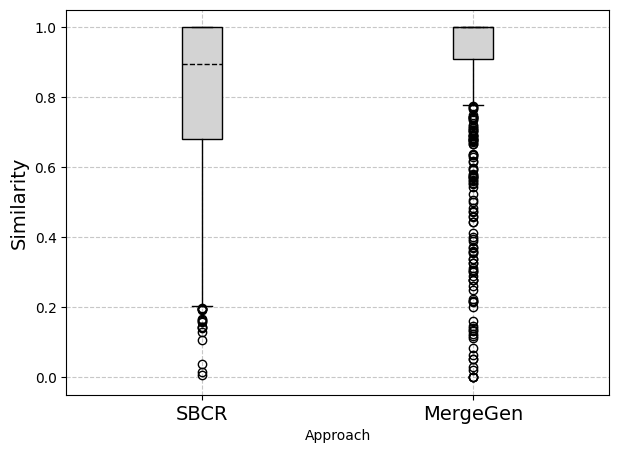

In [11]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_results_clean['sim_sbcr'], df_results_clean['sim_mergegen']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=True)

plt.xlabel('Approach')
plt.ylabel('Similarity', fontsize=14)
plt.xticks([1, 2], ['SBCR', 'MergeGen'], fontsize=14)
# plt.title('Similarity between random candidates and parents \n using each aggregation function', fontsize=16)
plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig('RQ2_CSharp_similarity_boxplot.png', dpi=300) 
plt.show()  

In [12]:
# Normality test
stat_shapiro_sbcr, p_shapiro_sbcr = stats.shapiro(df_results_clean['sim_sbcr'])
stat_shapiro_mergegen, p_shapiro_mergegen = stats.shapiro(df_results_clean['sim_mergegen'])

print(f"Shapiro-Wilk Test for SBCR: W={stat_shapiro_sbcr}, p={p_shapiro_sbcr}")
print(f"Shapiro-Wilk Test for MergeGen: W={stat_shapiro_mergegen}, p={p_shapiro_mergegen}")

# Homocedasticity test
stat_levene, p_levene = stats.levene(df_results_clean['sim_sbcr'], df_results_clean['sim_mergegen'])

print(f"Levene Test: W={stat_levene}, p={p_levene}")

Shapiro-Wilk Test for SBCR: W=0.8037074208259583, p=1.608354573616678e-26
Shapiro-Wilk Test for MergeGen: W=0.5740395784378052, p=5.334372055326573e-36
Levene Test: W=32.333979864005, p=1.6244471754093886e-08


In [13]:
# Not normal and not homocedastic. We use non-parametric paired test Wilcoxon
pg.wilcoxon(df_results_clean['sim_sbcr'], df_results_clean['sim_mergegen'], alternative='two-sided')

# https://pingouin-stats.org/build/html/index.html
# Interpretation: https://peterstatistics.com/Terms/Correlations/RankBiserialCorrelation.html

,W-val,alternative,p-val,RBC,CLES
Wilcoxon,29678.5,two-sided,1.877615e-17,-0.454494,0.334462


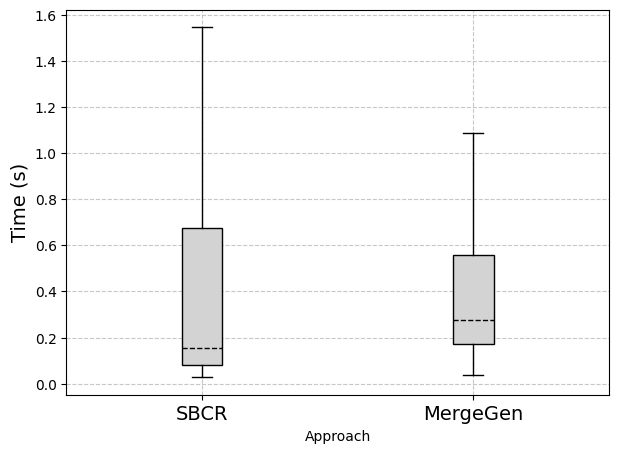

In [15]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_results_clean['time_sbcr'], df_results_clean['time_mergegen']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=False)

plt.xlabel('Approach')
plt.ylabel('Time (s)', fontsize=14)
plt.xticks([1, 2], ['SBCR', 'MergeGen'], fontsize=14)
# plt.title('Similarity between random candidates and parents \n using each aggregation function', fontsize=16)
plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig('RQ2_CSharp_time_boxplot.png', dpi=300) 
plt.show()  